In [6]:
%pip install --upgrade --force-reinstall pandas pyarrow

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached pyarrow-26.0.0-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached python_dateutil-3.0.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl (9.8 MB)
Using cached pyarrow-26.0.0-cp314-cp314-win_amd64.whl (29.2 MB)
Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl (12.7 MB)
Using cached python_dateutil-3.0.0-py2.py3-none-any.whl (94 kB)
Using cached six-1.17.0-py2.py3-none-any.whl (11 kB)
Using cached tzdata-2026.5-py2.py3-none-any.whl (347 kB)

  Attempting uninstall: tzdata

    Found existing installation: tzdata 2026.5

    Uninstalling tzdata-2026.5:

   ---------------------------------------- 0/6 [tzdata]
      Successfully uninstalled tzdata-2026.5

  You can safely remove it manually.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

print("¡Todas las librerías se importaron correctamente!")
print("Versión de XGBoost:", xgb.__version__)

KeyboardInterrupt: 

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from xgboost import XGBRegressor

print("¡Librerías cargadas correctamente!")
print("Versión de XGBoost:", xgb.__version__)

¡Librerías cargadas correctamente!
Versión de XGBoost: 3.4.1


In [11]:
url_viajes = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "trip-data/yellow_tripdata_2024-01.parquet"
)

url_zonas = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "misc/taxi_zone_lookup.csv"
)

print("URL de viajes:", url_viajes)
print("URL de zonas:", url_zonas)

URL de viajes: https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet
URL de zonas: https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv


In [12]:
import pandas as pd

print("Pandas está listo:", pd.__version__)
print("URL de viajes:", url_viajes)
print("URL de zonas:", url_zonas)

Pandas está listo: 3.0.6
URL de viajes: https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet
URL de zonas: https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv


In [13]:
viajes = pd.read_parquet(url_viajes)
zonas = pd.read_csv(url_zonas)

print("Dimensiones de viajes:", viajes.shape)
print("Dimensiones de zonas:", zonas.shape)

display(viajes.head())
display(zonas.head())

Dimensiones de viajes: (2964624, 19)
Dimensiones de zonas: (265, 4)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [14]:
print("Columnas disponibles:")
print(viajes.columns.tolist())

print("\nPeriodo de los datos:")
print("Inicio:", viajes["tpep_pickup_datetime"].min())
print("Fin:", viajes["tpep_pickup_datetime"].max())

print("\nTipos de datos:")
print(viajes[["tpep_pickup_datetime", "PULocationID"]].dtypes)

Columnas disponibles:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']

Periodo de los datos:
Inicio: 2002-12-31 22:59:39
Fin: 2024-02-01 00:01:15

Tipos de datos:
tpep_pickup_datetime    datetime64[us]
PULocationID                     int32
dtype: object


In [15]:
print("Primeras fechas:")
display(viajes["tpep_pickup_datetime"].sort_values().head(10))

print("\nCantidad de registros por año:")
display(
    viajes["tpep_pickup_datetime"]
    .dt.year
    .value_counts()
    .sort_index()
    .tail(10)
)

Primeras fechas:


53119     2002-12-31 22:59:39
53120     2002-12-31 22:59:39
2558056   2009-01-01 00:24:09
1230169   2009-01-01 23:30:39
10915     2009-01-01 23:58:40
369       2023-12-31 23:39:17
753       2023-12-31 23:41:02
3176      2023-12-31 23:47:28
2985      2023-12-31 23:49:12
8628      2023-12-31 23:54:27
Name: tpep_pickup_datetime, dtype: datetime64[us]


Cantidad de registros por año:


tpep_pickup_datetime
2002          2
2009          3
2023         10
2024    2964609
Name: count, dtype: int64

In [16]:
inicio = pd.Timestamp("2024-01-01")
fin = pd.Timestamp("2024-02-01")

enero = viajes[
    (viajes["tpep_pickup_datetime"] >= inicio)
    & (viajes["tpep_pickup_datetime"] < fin)
].copy()

print("Registros de enero de 2024:", len(enero))
print("Primera fecha:", enero["tpep_pickup_datetime"].min())
print("Última fecha:", enero["tpep_pickup_datetime"].max())

Registros de enero de 2024: 2964606
Primera fecha: 2024-01-01 00:00:00
Última fecha: 2024-01-31 23:59:55


In [17]:
enero["hora"] = enero["tpep_pickup_datetime"].dt.floor("h")

viajes_hora = (
    enero.groupby(["PULocationID", "hora"])
    .size()
    .reset_index(name="viajes")
)

print("Dimensiones de viajes_hora:", viajes_hora.shape)
print("\nPrimeras filas:")
display(viajes_hora.head())

Dimensiones de viajes_hora: (77530, 3)

Primeras filas:


,PULocationID,hora,viajes
0,1,2024-01-01 05:00:00,1
1,1,2024-01-01 06:00:00,4
2,1,2024-01-01 13:00:00,3
3,1,2024-01-01 14:00:00,6
4,1,2024-01-01 15:00:00,2


In [10]:
# 1. Convertir la fecha de recogida a formato datetime
viajes["tpep_pickup_datetime"] = pd.to_datetime(
    viajes["tpep_pickup_datetime"],
    errors="coerce"
)

# 2. Filtrar los viajes correspondientes a enero de 2024
inicio = pd.Timestamp("2024-01-01 00:00:00")
fin = pd.Timestamp("2024-02-01 00:00:00")

viajes = viajes.loc[
    (viajes["tpep_pickup_datetime"] >= inicio)
    & (viajes["tpep_pickup_datetime"] < fin)
].copy()

# 3. Eliminar registros sin fecha o zona de origen
viajes = viajes.dropna(
    subset=["tpep_pickup_datetime", "PULocationID"]
).copy()

# 4. Convertir la zona de origen a número entero
viajes["PULocationID"] = viajes["PULocationID"].astype(int)

# 5. Redondear la hora de recogida hacia abajo
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")

# 6. Contar viajes por zona y hora
conteo = (
    viajes.groupby(["PULocationID", "hora"])
    .size()
    .reset_index(name="viajes")
)

print("Viajes después de limpiar:", len(viajes))
print("Combinaciones de zona y hora:", len(conteo))

display(conteo.head(10))

Viajes después de limpiar: 2964606
Combinaciones de zona y hora: 77530


,PULocationID,hora,viajes
0,1,2024-01-01 05:00:00,1
1,1,2024-01-01 06:00:00,4
2,1,2024-01-01 13:00:00,3
3,1,2024-01-01 14:00:00,6
4,1,2024-01-01 15:00:00,2
5,1,2024-01-01 16:00:00,1
6,1,2024-01-01 17:00:00,4
7,1,2024-01-02 05:00:00,1
8,1,2024-01-02 06:00:00,1
9,1,2024-01-02 07:00:00,3


In [11]:
# 1. Calcular el total de viajes por zona en enero
conteo_zona = (
    viajes.groupby("PULocationID")
    .size()
    .reset_index(name="total_mes")
)

# 2. Excluir las zonas cuyo nombre sea "Unknown"
zonas_validas = zonas[
    zonas["Zone"].ne("Unknown")
].copy()

# 3. Seleccionar zonas para pronóstico
# Regla: mínimo 3,000 viajes durante enero
zonas_pronostico = (
    conteo_zona[
        conteo_zona["total_mes"] >= 3000
    ]
    .merge(
        zonas_validas,
        left_on="PULocationID",
        right_on="LocationID",
        how="inner"
    )
    .sort_values("total_mes", ascending=False)
    .reset_index(drop=True)
)

# 4. Seleccionar zonas para segmentación
# Regla: mínimo 500 viajes durante enero
zonas_segmentacion = (
    conteo_zona[
        conteo_zona["total_mes"] >= 500
    ]
    .merge(
        zonas_validas,
        left_on="PULocationID",
        right_on="LocationID",
        how="inner"
    )
    .sort_values("total_mes", ascending=False)
    .reset_index(drop=True)
)

# 5. Mostrar resultados con separadores de miles
print(f"Total de viajes procesados: {len(viajes):,}")
print(f"Zonas para pronóstico: {len(zonas_pronostico):,}")
print(f"Zonas para segmentación: {len(zonas_segmentacion):,}")

# 6. Tabla de zonas para pronóstico
print("\nZONAS PARA PRONÓSTICO (mínimo 3,000 viajes)")

display(
    zonas_pronostico[
        ["PULocationID", "Zone", "Borough", "total_mes"]
    ].style.format({
        "total_mes": "{:,.0f}"
    })
)

# 7. Tabla de zonas para segmentación
print("\nZONAS PARA SEGMENTACIÓN (mínimo 500 viajes)")

display(
    zonas_segmentacion[
        ["PULocationID", "Zone", "Borough", "total_mes"]
    ].style.format({
        "total_mes": "{:,.0f}"
    })
)

Total de viajes procesados: 2,964,606
Zonas para pronóstico: 59
Zonas para segmentación: 102

ZONAS PARA PRONÓSTICO (mínimo 3,000 viajes)


,PULocationID,Zone,Borough,total_mes
0,132,JFK Airport,Queens,"145,240"
1,161,Midtown Center,Manhattan,"143,469"
2,237,Upper East Side South,Manhattan,"142,707"
3,236,Upper East Side North,Manhattan,"136,464"
4,162,Midtown East,Manhattan,"106,717"
5,230,Times Sq/Theatre District,Manhattan,"106,324"
6,186,Penn Station/Madison Sq West,Manhattan,"104,522"
7,142,Lincoln Square East,Manhattan,"104,080"
8,138,LaGuardia Airport,Queens,"89,530"
9,239,Upper West Side South,Manhattan,"88,474"



ZONAS PARA SEGMENTACIÓN (mínimo 500 viajes)


,PULocationID,Zone,Borough,total_mes
0,132,JFK Airport,Queens,"145,240"
1,161,Midtown Center,Manhattan,"143,469"
2,237,Upper East Side South,Manhattan,"142,707"
3,236,Upper East Side North,Manhattan,"136,464"
4,162,Midtown East,Manhattan,"106,717"
5,230,Times Sq/Theatre District,Manhattan,"106,324"
6,186,Penn Station/Madison Sq West,Manhattan,"104,522"
7,142,Lincoln Square East,Manhattan,"104,080"
8,138,LaGuardia Airport,Queens,"89,530"
9,239,Upper West Side South,Manhattan,"88,474"


In [12]:
# Horas desde el 1 de enero hasta el 1 de febrero,
# incluyendo todas las horas necesarias para crear los lags.
horas = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-02-01 23:00:00",
    freq="h"
)

ids = zonas_pronostico["PULocationID"].tolist()

indice = pd.MultiIndex.from_product(
    [ids, horas],
    names=["PULocationID", "hora"]
)

demanda = (
    conteo
    .set_index(["PULocationID", "hora"])["viajes"]
    .reindex(indice, fill_value=0)
    .rename("viajes")
    .reset_index()
)

print("Filas de la serie completa:", len(demanda))
print("Número de zonas:", demanda["PULocationID"].nunique())
print("Horas por zona:", demanda.groupby("PULocationID").size().unique())

display(demanda.head(10))

Filas de la serie completa: 45312
Número de zonas: 59
Horas por zona: [768]


,PULocationID,hora,viajes
0,132,2024-01-01 00:00:00,150
1,132,2024-01-01 01:00:00,68
2,132,2024-01-01 02:00:00,21
3,132,2024-01-01 03:00:00,18
4,132,2024-01-01 04:00:00,26
5,132,2024-01-01 05:00:00,58
6,132,2024-01-01 06:00:00,203
7,132,2024-01-01 07:00:00,217
8,132,2024-01-01 08:00:00,141
9,132,2024-01-01 09:00:00,157


In [13]:
#4 PARTE 1 PRONÓSTICO

# Ordenar por zona y hora
demanda = demanda.sort_values(
    ["PULocationID", "hora"]
).reset_index(drop=True)

# Variables de calendario
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek
demanda["dia_mes"] = demanda["hora"].dt.day
demanda["fin_semana"] = (
    demanda["dia_semana"] >= 5
).astype(int)

# Indicador del feriado Martin Luther King Jr. Day
demanda["feriado"] = (
    demanda["hora"].dt.date == pd.Timestamp("2024-01-15").date()
).astype(int)

# Lags: valores pasados de la misma zona
grupo = demanda.groupby("PULocationID")["viajes"]

demanda["lag_24"] = grupo.shift(24)
demanda["lag_48"] = grupo.shift(48)
demanda["lag_168"] = grupo.shift(168)
demanda["lag_167"] = grupo.shift(167)
demanda["lag_169"] = grupo.shift(169)

# Promedio de viajes de las 24 horas anteriores
demanda["media_dia_ant"] = (
    demanda.groupby("PULocationID")["viajes"]
    .transform(lambda s: s.shift(24).rolling(24).mean())
)

# Comprobar las variables
columnas_revision = [
    "PULocationID",
    "hora",
    "viajes",
    "lag_24",
    "lag_48",
    "lag_168",
    "media_dia_ant",
    "hora_dia",
    "dia_semana",
    "feriado"
]

display(
    demanda[columnas_revision].head(30).style.format({
        "viajes": "{:,.0f}",
        "lag_24": "{:,.1f}",
        "lag_48": "{:,.1f}",
        "lag_168": "{:,.1f}",
        "media_dia_ant": "{:,.1f}"
    })
)

print("\nVariables creadas correctamente.")
print(f"Filas totales: {len(demanda):,}")
print(
    "Filas con lag_168 disponible:",
    f"{demanda['lag_168'].notna().sum():,}"
)


,PULocationID,hora,viajes,lag_24,lag_48,lag_168,media_dia_ant,hora_dia,dia_semana,feriado
0,4,2024-01-01 00:00:00,25,nan,nan,nan,nan,0,0,0
1,4,2024-01-01 01:00:00,29,nan,nan,nan,nan,1,0,0
2,4,2024-01-01 02:00:00,34,nan,nan,nan,nan,2,0,0
3,4,2024-01-01 03:00:00,31,nan,nan,nan,nan,3,0,0
4,4,2024-01-01 04:00:00,32,nan,nan,nan,nan,4,0,0
5,4,2024-01-01 05:00:00,8,nan,nan,nan,nan,5,0,0
6,4,2024-01-01 06:00:00,6,nan,nan,nan,nan,6,0,0
7,4,2024-01-01 07:00:00,4,nan,nan,nan,nan,7,0,0
8,4,2024-01-01 08:00:00,0,nan,nan,nan,nan,8,0,0
9,4,2024-01-01 09:00:00,1,nan,nan,nan,nan,9,0,0



Variables creadas correctamente.
Filas totales: 45,312
Filas con lag_168 disponible: 35,400


In [14]:
# CORREGIR VARIABLES TEMPORALES Y LAGS


demanda = demanda.sort_values(
    ["PULocationID", "hora"]
).reset_index(drop=True)

# Asegurar que la columna hora sea datetime
demanda["hora"] = pd.to_datetime(demanda["hora"])

# Variables de calendario
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek
demanda["dia_mes"] = demanda["hora"].dt.day
demanda["fin_semana"] = (
    demanda["dia_semana"] >= 5
).astype(int)

# El 15 de enero de 2024 fue el feriado
demanda["feriado"] = (
    (demanda["hora"].dt.month == 1)
    & (demanda["hora"].dt.day == 15)
).astype(int)

# Lags calculados dentro de cada zona
grupo = demanda.groupby("PULocationID")["viajes"]

demanda["lag_24"] = grupo.shift(24)
demanda["lag_48"] = grupo.shift(48)
demanda["lag_167"] = grupo.shift(167)
demanda["lag_168"] = grupo.shift(168)
demanda["lag_169"] = grupo.shift(169)

# Promedio de las 24 horas anteriores
demanda["media_dia_ant"] = (
    demanda.groupby("PULocationID")["viajes"]
    .transform(
        lambda s: s.shift(24).rolling(24).mean()
    )
)

# Verificar las variables
display(
    demanda[
        [
            "PULocationID",
            "hora",
            "viajes",
            "lag_24",
            "lag_48",
            "lag_168",
            "media_dia_ant",
            "hora_dia",
            "dia_semana",
            "feriado"
        ]
    ].head(30).style.format({
        "viajes": "{:,.0f}",
        "lag_24": "{:,.1f}",
        "lag_48": "{:,.1f}",
        "lag_168": "{:,.1f}",
        "media_dia_ant": "{:,.1f}"
    })
)

print("Columnas de demanda:")
print(demanda.columns.tolist())

print("\nTipos de datos:")
print(demanda.dtypes)

print("\nPrimeras 5 filas originales:")
display(demanda.head())

print("\nComprobación de hora:")
print(demanda["hora"].head().tolist())

print("\nComprobación de hora_dia:")
print(demanda["hora_dia"].head().tolist())

,PULocationID,hora,viajes,lag_24,lag_48,lag_168,media_dia_ant,hora_dia,dia_semana,feriado
0,4,2024-01-01 00:00:00,25,nan,nan,nan,nan,0,0,0
1,4,2024-01-01 01:00:00,29,nan,nan,nan,nan,1,0,0
2,4,2024-01-01 02:00:00,34,nan,nan,nan,nan,2,0,0
3,4,2024-01-01 03:00:00,31,nan,nan,nan,nan,3,0,0
4,4,2024-01-01 04:00:00,32,nan,nan,nan,nan,4,0,0
5,4,2024-01-01 05:00:00,8,nan,nan,nan,nan,5,0,0
6,4,2024-01-01 06:00:00,6,nan,nan,nan,nan,6,0,0
7,4,2024-01-01 07:00:00,4,nan,nan,nan,nan,7,0,0
8,4,2024-01-01 08:00:00,0,nan,nan,nan,nan,8,0,0
9,4,2024-01-01 09:00:00,1,nan,nan,nan,nan,9,0,0


Columnas de demanda:
['PULocationID', 'hora', 'viajes', 'hora_dia', 'dia_semana', 'dia_mes', 'fin_semana', 'feriado', 'lag_24', 'lag_48', 'lag_168', 'lag_167', 'lag_169', 'media_dia_ant']

Tipos de datos:
PULocationID              int64
hora             datetime64[us]
viajes                    int64
hora_dia                  int32
dia_semana                int32
dia_mes                   int32
fin_semana                int64
feriado                   int64
lag_24                  float64
lag_48                  float64
lag_168                 float64
lag_167                 float64
lag_169                 float64
media_dia_ant           float64
dtype: object

Primeras 5 filas originales:


,PULocationID,hora,viajes,hora_dia,dia_semana,dia_mes,fin_semana,feriado,lag_24,lag_48,lag_168,lag_167,lag_169,media_dia_ant
0,4,2024-01-01 00:00:00,25,0,0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,4,2024-01-01 01:00:00,29,1,0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,4,2024-01-01 02:00:00,34,2,0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2024-01-01 03:00:00,31,3,0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2024-01-01 04:00:00,32,4,0,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN



Comprobación de hora:
[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-01 01:00:00'), Timestamp('2024-01-01 02:00:00'), Timestamp('2024-01-01 03:00:00'), Timestamp('2024-01-01 04:00:00')]

Comprobación de hora_dia:
[0, 1, 2, 3, 4]


In [15]:
# COMPROBAR LAS VARIABLES TEMPORALES

print("Columnas:", demanda.columns.tolist())

print("\nTipos de datos:")
print(demanda[["hora", "hora_dia", "dia_semana", "feriado"]].dtypes)

print("\nPrimeras 5 filas:")
display(
    demanda[
        ["PULocationID", "hora", "viajes",
         "hora_dia", "dia_semana", "feriado"]
    ].head().to_string(index=False)
)

print("\nHoras del día:")
print(demanda["hora_dia"].head().tolist())

print("\nFechas marcadas como feriado:")
print(
    demanda.loc[demanda["feriado"] == 1, "hora"]
    .dt.strftime("%Y-%m-%d")
    .drop_duplicates()
    .tolist()[:10]
)

Columnas: ['PULocationID', 'hora', 'viajes', 'hora_dia', 'dia_semana', 'dia_mes', 'fin_semana', 'feriado', 'lag_24', 'lag_48', 'lag_168', 'lag_167', 'lag_169', 'media_dia_ant']

Tipos de datos:
hora          datetime64[us]
hora_dia               int32
dia_semana             int32
feriado                int64
dtype: object

Primeras 5 filas:


' PULocationID                hora  viajes  hora_dia  dia_semana  feriado\n            4 2024-01-01 00:00:00      25         0           0        0\n            4 2024-01-01 01:00:00      29         1           0        0\n            4 2024-01-01 02:00:00      34         2           0        0\n            4 2024-01-01 03:00:00      31         3           0        0\n            4 2024-01-01 04:00:00      32         4           0        0'


Horas del día:
[0, 1, 2, 3, 4]

Fechas marcadas como feriado:
['2024-01-15']


In [16]:
#Validar los rezagos

columnas_revision = [
    "PULocationID",
    "hora",
    "viajes",
    "hora_dia",
    "lag_24",
    "lag_48",
    "lag_168",
    "lag_167",
    "lag_169",
    "media_dia_ant"
]

print(demanda[columnas_revision].head(30).to_string(index=False))

 PULocationID                hora  viajes  hora_dia  lag_24  lag_48  lag_168  lag_167  lag_169  media_dia_ant
            4 2024-01-01 00:00:00      25         0     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 01:00:00      29         1     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 02:00:00      34         2     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 03:00:00      31         3     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 04:00:00      32         4     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 05:00:00       8         5     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 06:00:00       6         6     NaN     NaN      NaN      NaN      NaN            NaN
            4 2024-01-01 07:00:00       4         7     NaN     NaN      NaN      NaN      NaN            NaN
          

In [17]:
# Separar datos de entrenamiento y prueba

fecha_corte = pd.Timestamp("2024-01-25 00:00:00")
fecha_pronostico = pd.Timestamp("2024-02-01 00:00:00")

# Variables predictoras
variables = [
    "hora_dia",
    "dia_semana",
    "dia_mes",
    "fin_semana",
    "feriado",
    "lag_24",
    "lag_48",
    "lag_167",
    "lag_168",
    "lag_169",
    "media_dia_ant"
]

# Entrenamiento: 1 al 24 de enero
train = demanda.loc[
    demanda["hora"] < fecha_corte
].dropna(subset=variables + ["viajes"]).copy()

# Prueba: 25 al 31 de enero
test = demanda.loc[
    (demanda["hora"] >= fecha_corte) &
    (demanda["hora"] < fecha_pronostico)
].dropna(subset=variables + ["viajes"]).copy()

print("Filas de entrenamiento:", f"{len(train):,}")
print("Filas de prueba:", f"{len(test):,}")
print("Fecha inicial de entrenamiento:", train["hora"].min())
print("Fecha final de entrenamiento:", train["hora"].max())
print("Fecha inicial de prueba:", test["hora"].min())
print("Fecha final de prueba:", test["hora"].max())

Filas de entrenamiento: 24,013
Filas de prueba: 9,912
Fecha inicial de entrenamiento: 2024-01-08 01:00:00
Fecha final de entrenamiento: 2024-01-24 23:00:00
Fecha inicial de prueba: 2024-01-25 00:00:00
Fecha final de prueba: 2024-01-31 23:00:00


In [ ]:
# Entrenando Modelo

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Variables de entrada y variable objetivo
X_train = train[variables]
y_train = train["viajes"]

X_test = test[variables]
y_test = test["viajes"]

# Entrenar modelo XGBoost
modelo = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train, y_train)

# Predicciones para el período de prueba
predicciones = np.maximum(modelo.predict(X_test), 0)

# Modelo de referencia: misma hora de la semana anterior
prediccion_base = test["lag_168"].to_numpy()

# Calcular métricas
mae_xgb = mean_absolute_error(y_test, predicciones)
rmse_xgb = np.sqrt(mean_squared_error(y_test, predicciones))

mae_base = mean_absolute_error(y_test, prediccion_base)
rmse_base = np.sqrt(mean_squared_error(y_test, prediccion_base))

resultados = pd.DataFrame({
    "Modelo": ["XGBoost", "Referencia (lag_168)"],
    "MAE": [mae_xgb, mae_base],
    "RMSE": [rmse_xgb, rmse_base]
})

print("Resultados de evaluación:")
display(resultados.round(2))

# Comparar predicción con valores reales para una zona
zona_ejemplo = test["PULocationID"].iloc[0]

comparacion = test.loc[
    test["PULocationID"] == zona_ejemplo,
    ["hora", "PULocationID", "viajes", "lag_168"]
].copy()

comparacion["prediccion_xgboost"] = predicciones[
    test["PULocationID"].to_numpy() == zona_ejemplo
]

print(f"Ejemplo de predicciones para la zona {zona_ejemplo}:")
display(comparacion.head(24).round(2))

Resultados de evaluación:


,Modelo,MAE,RMSE
0,XGBoost,11.92,21.97
1,Referencia (lag_168),11.76,21.71


Ejemplo de predicciones para la zona 4:


C:\Users\karla.moreno\AppData\Local\Temp\ipykernel_15004\2545653602.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparacion.head(24).round(2))


,hora,PULocationID,viajes,lag_168,prediccion_xgboost
576,2024-01-25 00:00:00,4,4,2.0,3.76
577,2024-01-25 01:00:00,4,2,1.0,1.04
578,2024-01-25 02:00:00,4,0,0.0,0.76
579,2024-01-25 03:00:00,4,0,0.0,0.28
580,2024-01-25 04:00:00,4,0,0.0,0.09
581,2024-01-25 05:00:00,4,1,0.0,0.43
582,2024-01-25 06:00:00,4,3,5.0,1.97
583,2024-01-25 07:00:00,4,4,5.0,6.33
584,2024-01-25 08:00:00,4,7,8.0,6.16
585,2024-01-25 09:00:00,4,11,6.0,6.74


In [21]:
# Generar pronósticos para el 1 de febrero

# Crear las 24 horas del 1 de febrero para cada zona
fecha_objetivo = pd.Timestamp("2024-02-01")
horas_objetivo = pd.date_range(
    start=fecha_objetivo,
    periods=24,
    freq="h"
)

ids_zonas = zonas_pronostico["PULocationID"].tolist()

pronostico = pd.MultiIndex.from_product(
    [ids_zonas, horas_objetivo],
    names=["PULocationID", "hora"]
).to_frame(index=False)

# Variables de calendario
pronostico["hora_dia"] = pronostico["hora"].dt.hour
pronostico["dia_semana"] = pronostico["hora"].dt.dayofweek
pronostico["dia_mes"] = pronostico["hora"].dt.day
pronostico["fin_semana"] = (
    pronostico["dia_semana"] >= 5
).astype(int)
pronostico["feriado"] = 0

# Recuperar rezagos desde la serie histórica completa
historial = demanda.sort_values(
    ["PULocationID", "hora"]
).copy()

historial_por_zona = {
    zona_id: grupo.set_index("hora")["viajes"]
    for zona_id, grupo in historial.groupby("PULocationID")
}

for col, desplazamiento in [
    ("lag_24", 24),
    ("lag_48", 48),
    ("lag_167", 167),
    ("lag_168", 168),
    ("lag_169", 169)
]:
    pronostico[col] = [
        historial_por_zona[zona_id].get(
            hora - pd.Timedelta(hours=desplazamiento),
            np.nan
        )
        for zona_id, hora in zip(
            pronostico["PULocationID"],
            pronostico["hora"]
        )
    ]

# Media de las 24 horas anteriores
pronostico["media_dia_ant"] = [
    historial_por_zona[zona_id]
    .reindex(pd.date_range(hora - pd.Timedelta(hours=24),
                           periods=24, freq="h"))
    .mean()
    for zona_id, hora in zip(
        pronostico["PULocationID"],
        pronostico["hora"]
    )
]

print("Filas del pronóstico:", f"{len(pronostico):,}")
print("Valores faltantes en variables predictoras:")
print(pronostico[variables].isna().sum())

display(pronostico.head(10).round(2))

Filas del pronóstico: 1,416
Valores faltantes en variables predictoras:
hora_dia         0
dia_semana       0
dia_mes          0
fin_semana       0
feriado          0
lag_24           0
lag_48           0
lag_167          0
lag_168          0
lag_169          0
media_dia_ant    0
dtype: int64


C:\Users\karla.moreno\AppData\Local\Temp\ipykernel_15004\1933884480.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(pronostico.head(10).round(2))


,PULocationID,hora,hora_dia,dia_semana,dia_mes,fin_semana,feriado,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant
0,132,2024-02-01 00:00:00,0,3,1,0,0,164,226,17,143,289,145.71
1,132,2024-02-01 01:00:00,1,3,1,0,0,24,60,14,17,143,138.88
2,132,2024-02-01 02:00:00,2,3,1,0,0,2,14,5,14,17,137.88
3,132,2024-02-01 03:00:00,3,3,1,0,0,5,7,7,5,14,137.79
4,132,2024-02-01 04:00:00,4,3,1,0,0,19,16,90,7,5,137.58
5,132,2024-02-01 05:00:00,5,3,1,0,0,63,96,96,90,7,136.79
6,132,2024-02-01 06:00:00,6,3,1,0,0,87,182,140,96,90,134.17
7,132,2024-02-01 07:00:00,7,3,1,0,0,74,100,129,140,96,130.54
8,132,2024-02-01 08:00:00,8,3,1,0,0,89,88,83,129,140,127.46
9,132,2024-02-01 09:00:00,9,3,1,0,0,89,90,114,83,129,123.75


In [22]:
# Generar las predicciones de XGBoost

# Generar predicciones para el 1 de febrero
pronostico["prediccion_xgboost"] = np.maximum(
    modelo.predict(pronostico[variables]),
    0
)

# Pronóstico de referencia: misma hora de la semana anterior
pronostico["prediccion_base"] = pronostico["lag_168"]

# Resumen de las predicciones
print("Resumen de predicciones de XGBoost:")
print(
    pronostico["prediccion_xgboost"]
    .describe()
    .round(2)
    .to_string()
)

print("\nDemanda total estimada para el 1 de febrero:")
print(
    "XGBoost:",
    f'{pronostico["prediccion_xgboost"].sum():,.0f} viajes'
)
print(
    "Referencia:",
    f'{pronostico["prediccion_base"].sum():,.0f} viajes'
)

# Mostrar las primeras 10 filas
print("\nPrimeras predicciones:")
print(
    pronostico[
        [
            "PULocationID",
            "hora",
            "lag_168",
            "prediccion_xgboost",
            "prediccion_base"
        ]
    ].head(10).to_string(index=False)
)

Resumen de predicciones de XGBoost:
count    1416.00
mean       79.08
std        90.84
min         0.00
25%         8.82
50%        43.49
75%       129.87
max       553.88

Demanda total estimada para el 1 de febrero:
XGBoost: 111,974 viajes
Referencia: 108,036 viajes

Primeras predicciones:
 PULocationID                hora  lag_168  prediccion_xgboost  prediccion_base
          132 2024-02-01 00:00:00      143          127.283424              143
          132 2024-02-01 01:00:00       17           36.601841               17
          132 2024-02-01 02:00:00       14           10.746246               14
          132 2024-02-01 03:00:00        5            5.326008                5
          132 2024-02-01 04:00:00        7           18.039927                7
          132 2024-02-01 05:00:00       90           65.811920               90
          132 2024-02-01 06:00:00       96           92.509285               96
          132 2024-02-01 07:00:00      140          108.443626     

In [23]:
# Construir intervalos de incertidumbre

# Crear una tabla de evaluación con predicciones y errores
evaluacion = test[
    ["PULocationID", "hora", "viajes"]
].copy()

evaluacion["prediccion"] = predicciones
evaluacion["error"] = (
    evaluacion["viajes"] - evaluacion["prediccion"]
)
evaluacion["error_absoluto"] = evaluacion["error"].abs()

# Revisar la distribución de los errores
print("Resumen de errores absolutos:")
print(
    evaluacion["error_absoluto"]
    .describe(percentiles=[0.50, 0.80, 0.90, 0.95])
    .round(2)
    .to_string()
)

# Calcular cuantiles de los errores
q80 = evaluacion["error_absoluto"].quantile(0.80)
q90 = evaluacion["error_absoluto"].quantile(0.90)
q95 = evaluacion["error_absoluto"].quantile(0.95)

print("\nCuantiles del error absoluto:")
print(f"80%: {q80:.2f} viajes")
print(f"90%: {q90:.2f} viajes")
print(f"95%: {q95:.2f} viajes")

Resumen de errores absolutos:
count    9912.00
mean       11.92
std        18.46
min         0.00
50%         5.47
80%        17.40
90%        29.80
95%        45.36
max       297.78

Cuantiles del error absoluto:
80%: 17.40 viajes
90%: 29.80 viajes
95%: 45.36 viajes


In [24]:
# Crear los cuantiles p10, p50 y p90

# Errores con signo en el período de prueba
errores = evaluacion["viajes"] - evaluacion["prediccion"]

# Cuantiles empíricos de los errores
error_p10 = errores.quantile(0.10)
error_p50 = errores.quantile(0.50)
error_p90 = errores.quantile(0.90)

print("Cuantiles de los errores con signo:")
print(f"Error p10: {error_p10:.2f}")
print(f"Error p50: {error_p50:.2f}")
print(f"Error p90: {error_p90:.2f}")

# Aplicarlos a las predicciones del 1 de febrero
pronostico["p10"] = np.maximum(
    pronostico["prediccion_xgboost"] + error_p10, 0
)
pronostico["p50"] = np.maximum(
    pronostico["prediccion_xgboost"] + error_p50, 0
)
pronostico["p90"] = np.maximum(
    pronostico["prediccion_xgboost"] + error_p90, 0
)

print("\nPronóstico con cuantiles para el 1 de febrero:")
print(
    pronostico[
        [
            "PULocationID",
            "hora",
            "p10",
            "p50",
            "p90"
        ]
    ].head(10).round(2).to_string(index=False)
)

# Verificar que los cuantiles estén ordenados
orden_correcto = (
    (pronostico["p10"] <= pronostico["p50"]) &
    (pronostico["p50"] <= pronostico["p90"])
).all()

print("\n¿Los cuantiles están ordenados correctamente?", orden_correcto)

Cuantiles de los errores con signo:
Error p10: -13.87
Error p50: 0.57
Error p90: 20.63

Pronóstico con cuantiles para el 1 de febrero:
 PULocationID                hora        p10        p50        p90
          132 2024-02-01 00:00:00 113.410004 127.849998 147.910004
          132 2024-02-01 01:00:00  22.730000  37.169998  57.230000
          132 2024-02-01 02:00:00   0.000000  11.310000  31.370001
          132 2024-02-01 03:00:00   0.000000   5.890000  25.950001
          132 2024-02-01 04:00:00   4.170000  18.610001  38.669998
          132 2024-02-01 05:00:00  51.939999  66.379997  86.440002
          132 2024-02-01 06:00:00  78.639999  93.070000 113.129997
          132 2024-02-01 07:00:00  94.570000 109.010002 129.070007
          132 2024-02-01 08:00:00  93.699997 108.129997 128.190002
          132 2024-02-01 09:00:00  94.110001 108.550003 128.610001

¿Los cuantiles están ordenados correctamente? True


C:\Users\karla.moreno\AppData\Local\Temp\ipykernel_15004\2686609093.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2).to_string(index=False)


In [25]:
# Evaluar la cobertura de los intervalos

# Construir cuantiles para el período de prueba
evaluacion["p10"] = np.maximum(
    evaluacion["prediccion"] + error_p10, 0
)
evaluacion["p50"] = np.maximum(
    evaluacion["prediccion"] + error_p50, 0
)
evaluacion["p90"] = np.maximum(
    evaluacion["prediccion"] + error_p90, 0
)

# Cobertura: porcentaje de valores reales dentro del intervalo
cobertura = (
    (evaluacion["viajes"] >= evaluacion["p10"]) &
    (evaluacion["viajes"] <= evaluacion["p90"])
).mean() * 100

# Ancho promedio del intervalo
ancho_promedio = (
    evaluacion["p90"] - evaluacion["p10"]
).mean()

# Error de la predicción central
mae_p50 = mean_absolute_error(
    evaluacion["viajes"],
    evaluacion["p50"]
)

print(f"Cobertura observada p10-p90: {cobertura:.2f}%")
print(f"Ancho promedio del intervalo: {ancho_promedio:.2f} viajes")
print(f"MAE de p50: {mae_p50:.2f} viajes")

Cobertura observada p10-p90: 79.98%
Ancho promedio del intervalo: 31.63 viajes
MAE de p50: 11.90 viajes


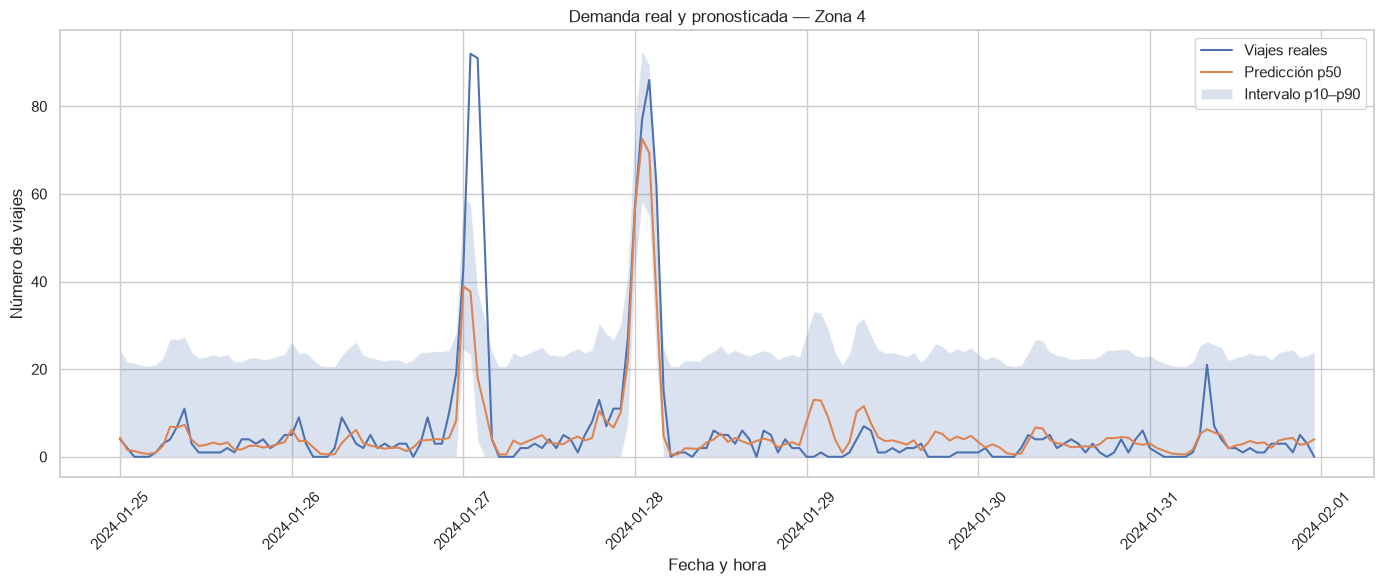

In [26]:
#Graficar demanda real frente a predicción

import matplotlib.pyplot as plt

# Elegir una zona con datos en el período de prueba
zona_ejemplo = 4

grafica = evaluacion[
    evaluacion["PULocationID"] == zona_ejemplo
].sort_values("hora").copy()

plt.figure(figsize=(14, 6))

plt.plot(
    grafica["hora"],
    grafica["viajes"],
    label="Viajes reales",
    linewidth=1.5
)

plt.plot(
    grafica["hora"],
    grafica["p50"],
    label="Predicción p50",
    linewidth=1.5
)

plt.fill_between(
    grafica["hora"],
    grafica["p10"],
    grafica["p90"],
    alpha=0.2,
    label="Intervalo p10–p90"
)

plt.title(
    f"Demanda real y pronosticada — Zona {zona_ejemplo}"
)
plt.xlabel("Fecha y hora")
plt.ylabel("Número de viajes")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# Preparar las características para la segmentación

# Trabajar únicamente con enero de 2024
viajes_enero = viajes.loc[
    (viajes["tpep_pickup_datetime"] >= "2024-01-01") &
    (viajes["tpep_pickup_datetime"] < "2024-02-01")
].copy()

# Horas completas de enero
horas_enero = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-01-31 23:00:00",
    freq="h"
)

# Zonas elegibles para segmentación: mínimo 500 viajes
ids_segmentacion = zonas_segmentacion["PULocationID"].tolist()

# Contar viajes por zona y hora
conteo_segmentacion = (
    viajes_enero
    .groupby(["PULocationID", "hora"])
    .size()
    .rename("viajes")
)

# Crear todas las combinaciones de zona y hora,
# rellenando con cero las horas sin viajes
indice_segmentacion = pd.MultiIndex.from_product(
    [ids_segmentacion, horas_enero],
    names=["PULocationID", "hora"]
)

serie_segmentacion = (
    conteo_segmentacion
    .reindex(indice_segmentacion, fill_value=0)
    .rename("viajes")
    .reset_index()
)

print("Zonas para segmentación:", len(ids_segmentacion))
print("Horas por zona:", serie_segmentacion.groupby(
    "PULocationID"
).size().unique())

print("Filas de la serie:", f"{len(serie_segmentacion):,}")
display(serie_segmentacion.head().to_string(index=False))

Zonas para segmentación: 102
Horas por zona: [744]
Filas de la serie: 75,888


' PULocationID                hora  viajes\n          132 2024-01-01 00:00:00     150\n          132 2024-01-01 01:00:00      68\n          132 2024-01-01 02:00:00      21\n          132 2024-01-01 03:00:00      18\n          132 2024-01-01 04:00:00      26'

In [29]:
# Crear las características de cada zona

# Variables de calendario
serie_segmentacion["hora_dia"] = serie_segmentacion["hora"].dt.hour
serie_segmentacion["dia_semana"] = (
    serie_segmentacion["hora"].dt.dayofweek
)
serie_segmentacion["fin_semana"] = (
    serie_segmentacion["dia_semana"] >= 5
).astype(int)

# Resumen general por zona
caracteristicas = (
    serie_segmentacion
    .groupby("PULocationID")
    .agg(
        total_viajes=("viajes", "sum"),
        promedio_hora=("viajes", "mean"),
        desviacion_hora=("viajes", "std"),
        maximo_hora=("viajes", "max"),
        horas_sin_demanda=("viajes", lambda s: (s == 0).mean())
    )
)

# Demanda promedio durante días laborables y fines de semana
promedios_dia = serie_segmentacion.pivot_table(
    index="PULocationID",
    columns="fin_semana",
    values="viajes",
    aggfunc="mean",
    fill_value=0
).rename(columns={
    0: "promedio_laborable",
    1: "promedio_fin_semana"
})

caracteristicas = caracteristicas.join(
    promedios_dia,
    how="left"
)

# Perfil de demanda: promedio para cada hora del día
perfil_horario = serie_segmentacion.pivot_table(
    index="PULocationID",
    columns="hora_dia",
    values="viajes",
    aggfunc="mean",
    fill_value=0
)

perfil_horario.columns = [
    f"demanda_hora_{h:02d}" for h in perfil_horario.columns
]

caracteristicas = caracteristicas.join(
    perfil_horario,
    how="left"
)

# Incorporar los nombres de las zonas y sus boroughs
informacion_zonas = zonas_segmentacion[
    ["PULocationID", "Zone", "Borough"]
].drop_duplicates("PULocationID").set_index("PULocationID")

caracteristicas = caracteristicas.join(informacion_zonas)

print("Número de zonas:", len(caracteristicas))
print("Número de características numéricas:", len(
    caracteristicas.select_dtypes(include="number").columns
))

display(caracteristicas.head().round(2))

Número de zonas: 102
Número de características numéricas: 31


,total_viajes,promedio_hora,desviacion_hora,maximo_hora,horas_sin_demanda,promedio_laborable,promedio_fin_semana,demanda_hora_00,demanda_hora_01,demanda_hora_02,...,demanda_hora_16,demanda_hora_17,demanda_hora_18,demanda_hora_19,demanda_hora_20,demanda_hora_21,demanda_hora_22,demanda_hora_23,Zone,Borough
PULocationID,,,,,,,,,,,,,,,,,,,,,
4,3568,4.80,10.21,92,0.19,2.91,10.21,12.61,17.42,14.39,...,2.45,2.45,3.10,3.74,3.13,3.94,4.55,8.35,Alphabet City,Manhattan
7,1811,2.43,2.59,28,0.20,2.25,2.97,1.10,1.45,1.23,...,3.52,2.68,2.26,2.42,1.65,1.94,1.13,1.84,Astoria,Queens
10,999,1.34,1.48,7,0.36,1.39,1.19,0.90,0.32,0.13,...,3.06,1.97,0.90,1.52,1.48,1.68,1.77,1.19,Baisley Park,Queens
12,875,1.18,2.19,21,0.61,1.17,1.20,0.16,0.00,0.03,...,4.32,2.29,0.71,0.32,0.52,0.26,0.29,0.13,Battery Park,Manhattan
13,15877,21.34,20.07,102,0.11,23.74,14.44,2.68,1.39,0.52,...,40.26,52.52,55.58,41.68,29.26,21.16,10.71,5.42,Battery Park City,Manhattan


In [30]:
# Verificar que las características estén listas

columnas_numericas = caracteristicas.select_dtypes(
    include="number"
).columns

X_segmentacion = caracteristicas[columnas_numericas].copy()

print("Valores faltantes:", X_segmentacion.isna().sum().sum())
print("Valores infinitos:", np.isinf(X_segmentacion.to_numpy()).sum())
print("Dimensiones de X:", X_segmentacion.shape)

Valores faltantes: 0
Valores infinitos: 0
Dimensiones de X: (102, 31)


In [31]:
# Escalar las características y seleccionar el número de grupos

# Escalar los datos
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Estandarizar las características numéricas
escalador = StandardScaler()

X_escalado = escalador.fit_transform(X_segmentacion)

print("Dimensiones de los datos escalados:", X_escalado.shape)
print("Promedio aproximado de la primera característica:",
      round(X_escalado[:, 0].mean(), 4))
print("Desviación estándar aproximada:",
      round(X_escalado[:, 0].std(), 4))

Dimensiones de los datos escalados: (102, 31)
Promedio aproximado de la primera característica: -0.0
Desviación estándar aproximada: 1.0


,k,silhouette_score,inercia
0,2,0.6245,1266.1023
1,3,0.5731,876.2207
2,4,0.6028,656.9034
3,5,0.4656,548.1311
4,6,0.5635,445.3464
5,7,0.4239,390.3847


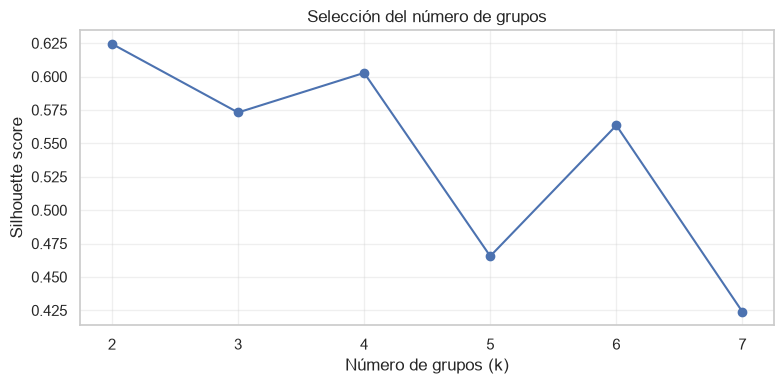

In [32]:
# Probar distintos valores de K

resultados_k = []

for k in range(2, 8):
    modelo_k = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo_k.fit_predict(X_escalado)

    silueta = silhouette_score(
        X_escalado,
        etiquetas
    )

    resultados_k.append({
        "k": k,
        "silhouette_score": silueta,
        "inercia": modelo_k.inertia_
    })

tabla_k = pd.DataFrame(resultados_k)

display(tabla_k.round(4))

# Graficar el silhouette score
plt.figure(figsize=(8, 4))
plt.plot(
    tabla_k["k"],
    tabla_k["silhouette_score"],
    marker="o"
)
plt.xticks(range(2, 8))
plt.xlabel("Número de grupos (k)")
plt.ylabel("Silhouette score")
plt.title("Selección del número de grupos")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Entrenar el modelo KMeans definitivo

# Entrenar KMeans con el número de grupos seleccionado
k_optimo = 2

modelo_kmeans = KMeans(
    n_clusters=k_optimo,
    random_state=42,
    n_init=10
)

caracteristicas["cluster"] = modelo_kmeans.fit_predict(
    X_escalado
)

print(f"Número de grupos: {k_optimo:,}")

print("\nCantidad de zonas por grupo:")
print(
    caracteristicas["cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nEjemplos de zonas asignadas:")

display(
    caracteristicas[
        ["Zone", "Borough", "total_viajes", "cluster"]
    ]
    .sort_values(
        ["cluster", "total_viajes"],
        ascending=[True, False]
    )
    .head(15)
    .style.format({
        "total_viajes": "{:,.0f}",
        "cluster": "{:,.0f}"
    })
)

Número de grupos: 2

Cantidad de zonas por grupo:
cluster
0    31
1    71

Ejemplos de zonas asignadas:


,Zone,Borough,total_viajes,cluster
PULocationID,,,,
132,JFK Airport,Queens,"145,240",0
161,Midtown Center,Manhattan,"143,469",0
237,Upper East Side South,Manhattan,"142,707",0
236,Upper East Side North,Manhattan,"136,464",0
162,Midtown East,Manhattan,"106,717",0
230,Times Sq/Theatre District,Manhattan,"106,324",0
186,Penn Station/Madison Sq West,Manhattan,"104,522",0
142,Lincoln Square East,Manhattan,"104,080",0
138,LaGuardia Airport,Queens,"89,530",0


Varianza explicada por PC1: 77.16%
Varianza explicada por PC2: 13.18%
Varianza explicada total: 90.34%


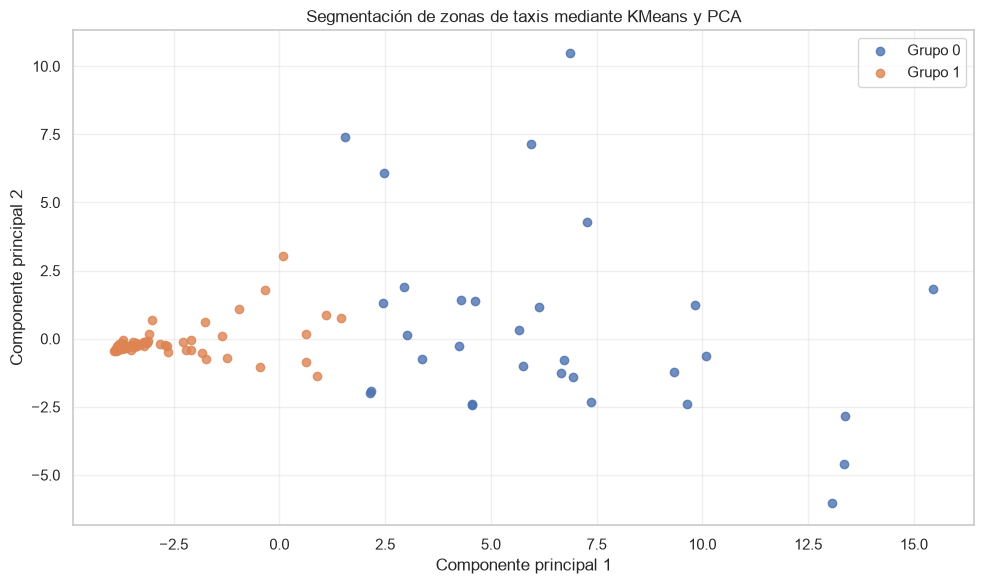

In [35]:
# visualizar los grupos mediante PCA

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reducir las 31 características a dos componentes principales
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_escalado)

caracteristicas["PC1"] = componentes[:, 0]
caracteristicas["PC2"] = componentes[:, 1]

# Mostrar varianza explicada
varianza_pc1 = pca.explained_variance_ratio_[0] * 100
varianza_pc2 = pca.explained_variance_ratio_[1] * 100
varianza_total = varianza_pc1 + varianza_pc2

print(f"Varianza explicada por PC1: {varianza_pc1:,.2f}%")
print(f"Varianza explicada por PC2: {varianza_pc2:,.2f}%")
print(f"Varianza explicada total: {varianza_total:,.2f}%")

# Crear la gráfica
plt.figure(figsize=(10, 6))

for cluster_id in sorted(caracteristicas["cluster"].unique()):
    datos_cluster = caracteristicas[
        caracteristicas["cluster"] == cluster_id
    ]

    plt.scatter(
        datos_cluster["PC1"],
        datos_cluster["PC2"],
        label=f"Grupo {cluster_id}",
        alpha=0.8
    )

plt.title("Segmentación de zonas de taxis mediante KMeans y PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# Comparar las características de los grupos

# Perfil promedio de cada grupo

resumen_clusters = caracteristicas.groupby("cluster").agg(
    cantidad_zonas=("Zone", "count"),
    viajes_promedio=("total_viajes", "mean"),
    viajes_mediana=("total_viajes", "median"),
    promedio_hora=("promedio_hora", "mean"),
    desviacion_promedio=("desviacion_hora", "mean"),
    demanda_laborable=("promedio_laborable", "mean"),
    demanda_fin_semana=("promedio_fin_semana", "mean")
)

display(
    resumen_clusters.style.format({
        "cantidad_zonas": "{:,.0f}",
        "viajes_promedio": "{:,.2f}",
        "viajes_mediana": "{:,.2f}",
        "promedio_hora": "{:,.2f}",
        "desviacion_promedio": "{:,.2f}",
        "demanda_laborable": "{:,.2f}",
        "demanda_fin_semana": "{:,.2f}"
    })
)

,cantidad_zonas,viajes_promedio,viajes_mediana,promedio_hora,desviacion_promedio,demanda_laborable,demanda_fin_semana
cluster,,,,,,,
0,31,"78,929.97","73,946.00",106.09,80.55,106.55,104.75
1,70,"6,963.27","1,658.00",9.36,7.93,9.23,9.74


In [38]:
print("Zonas únicas:", caracteristicas.index.nunique())
print("\nConteo de grupos:")
print(caracteristicas["cluster"].value_counts().sort_index().to_string())

print("\nFilas por grupo:")
print(caracteristicas.groupby("cluster").size().to_string())

print("\nZonas con nombre faltante:")
print(caracteristicas["Zone"].isna().sum())

print("\nResumen actualizado:")
resumen_clusters = caracteristicas.groupby("cluster").agg(
    cantidad_zonas=("PULocationID", "size")
    if "PULocationID" in caracteristicas.columns
    else ("Zone", "size"),
    viajes_promedio=("total_viajes", "mean"),
    viajes_mediana=("total_viajes", "median"),
    promedio_hora=("promedio_hora", "mean"),
    desviacion_promedio=("desviacion_hora", "mean"),
    demanda_laborable=("promedio_laborable", "mean"),
    demanda_fin_semana=("promedio_fin_semana", "mean")
)

display(resumen_clusters.style.format("{:,.2f}"))

Zonas únicas: 102

Conteo de grupos:
cluster
0    31
1    71

Filas por grupo:
cluster
0    31
1    71

Zonas con nombre faltante:
1

Resumen actualizado:


,cantidad_zonas,viajes_promedio,viajes_mediana,promedio_hora,desviacion_promedio,demanda_laborable,demanda_fin_semana
cluster,,,,,,,
0,31.00,"78,929.97","73,946.00",106.09,80.55,106.55,104.75
1,71.00,"6,963.27","1,658.00",9.36,7.93,9.23,9.74


In [48]:
# Preparar la recomendación de zonas según costos

# Definir costos de decisión

print("Introduce los costos para calcular el umbral de demanda.")

costo_pasajero_perdido = float(
    input("Costo estimado de perder un pasajero: ")
)

costo_taxi_espera = float(
    input("Costo estimado de mantener un taxi esperando: ")
)

if costo_pasajero_perdido <= 0 or costo_taxi_espera <= 0:
    raise ValueError("Los costos deben ser mayores que cero.")

# Umbral basado en costos
umbral = costo_pasajero_perdido / (
    costo_pasajero_perdido + costo_taxi_espera
)

print(f"\nCosto de pasajero perdido: {costo_pasajero_perdido:,.2f}")
print(f"Costo de taxi en espera: {costo_taxi_espera:,.2f}")
print(f"Umbral calculado: {umbral:.2%}")

Introduce los costos para calcular el umbral de demanda.

Costo de pasajero perdido: 40.00
Costo de taxi en espera: 10.00
Umbral calculado: 80.00%


In [49]:
# Preparar la recomendación por zona

# Preparar tabla de recomendación por zona

recomendacion = pronostico.groupby("PULocationID").agg(
    demanda_estimada=("p50", "sum"),
    demanda_baja=("p10", "sum"),
    demanda_alta=("p90", "sum"),
    demanda_semana_anterior=("prediccion_base", "sum")
).reset_index()

# Incorporar nombre y borough
recomendacion = recomendacion.merge(
    zonas_pronostico[
        ["PULocationID", "Zone", "Borough", "total_mes"]
    ].drop_duplicates("PULocationID"),
    on="PULocationID",
    how="left"
)

# Diferencia respecto a la referencia semanal
recomendacion["diferencia_referencia"] = (
    recomendacion["demanda_estimada"]
    - recomendacion["demanda_semana_anterior"]
)

# Ordenar de mayor a menor demanda estimada
recomendacion = recomendacion.sort_values(
    "demanda_estimada",
    ascending=False
).reset_index(drop=True)

# Mostrar las 15 zonas con mayor demanda
columnas_mostrar = [
    "PULocationID",
    "Zone",
    "Borough",
    "demanda_estimada",
    "demanda_baja",
    "demanda_alta",
    "demanda_semana_anterior",
    "diferencia_referencia"
]

print("Primeras 15 zonas según demanda estimada:")

display(
    recomendacion[columnas_mostrar]
    .head(15)
    .style.format({
        "PULocationID": "{:,.0f}",
        "demanda_estimada": "{:,.0f}",
        "demanda_baja": "{:,.0f}",
        "demanda_alta": "{:,.0f}",
        "demanda_semana_anterior": "{:,.0f}",
        "diferencia_referencia": "{:+,.0f}"
    })
)

Primeras 15 zonas según demanda estimada:


,PULocationID,Zone,Borough,demanda_estimada,demanda_baja,demanda_alta,demanda_semana_anterior,diferencia_referencia
0,161,Midtown Center,Manhattan,"6,001","5,685","6,483","6,423",-422
1,237,Upper East Side South,Manhattan,"5,516","5,200","5,997","6,120",-604
2,236,Upper East Side North,Manhattan,"5,387","5,066","5,868","5,522",-135
3,162,Midtown East,Manhattan,"4,551","4,225","5,032","4,753",-202
4,230,Times Sq/Theatre District,Manhattan,"4,034","3,687","4,515","3,873",+161
5,186,Penn Station/Madison Sq West,Manhattan,"3,826","3,489","4,307","4,080",-254
6,132,JFK Airport,Queens,"3,725","3,390","4,206","4,034",-309
7,163,Midtown North,Manhattan,"3,611","3,293","4,092","3,472",+139
8,142,Lincoln Square East,Manhattan,"3,529","3,206","4,011","3,412",+117
9,170,Murray Hill,Manhattan,"3,509","3,192","3,991","3,691",-182


In [51]:
# Exportar resultados de demanda por zona

archivo_csv = "recomendacion_zonas_taxi.csv"

recomendacion.to_csv(
    archivo_csv,
    index=False,
    encoding="utf-8-sig"
)

print(f"Archivo creado: {archivo_csv}")
print(f"Total de zonas incluidas: {len(recomendacion):,}")
print(
    "Demanda estimada total:",
    f'{recomendacion["demanda_estimada"].sum():,.0f}'
)

Archivo creado: recomendacion_zonas_taxi.csv
Total de zonas incluidas: 59
Demanda estimada total: 112,775


In [55]:
# Calcular el cuantil óptimo y recomendar taxis

# Costos económicos
costo_pasajero_perdido = 40
costo_taxi_ocioso = 10

# Calcular el cuantil óptimo
cuantil_optimo = (
    costo_pasajero_perdido /
    (costo_pasajero_perdido + costo_taxi_ocioso)
)

print(f"Cuantil óptimo: {cuantil_optimo:.2%}")

# Crear recomendación por hora
plan_taxis = pronostico[
    ["PULocationID", "hora", "p10", "p50", "p90", "prediccion_base"]
].copy()

# Interpolar según el cuantil óptimo
if cuantil_optimo <= 0.50:
    proporcion = cuantil_optimo / 0.50

    plan_taxis["taxis_recomendados"] = (
        plan_taxis["p10"] +
        proporcion * (plan_taxis["p50"] - plan_taxis["p10"])
    )

else:
    proporcion = (cuantil_optimo - 0.50) / 0.40

    plan_taxis["taxis_recomendados"] = (
        plan_taxis["p50"] +
        proporcion * (plan_taxis["p90"] - plan_taxis["p50"])
    )

# Evitar valores negativos y conservar dos decimales
plan_taxis["taxis_recomendados"] = (
    plan_taxis["taxis_recomendados"].clip(lower=0).round(2)
)

plan_taxis["taxis_p50"] = (
    plan_taxis["p50"].clip(lower=0).round(2)
)

plan_taxis["taxis_semana_anterior"] = (
    plan_taxis["prediccion_base"].clip(lower=0).round(2)
)

# Mostrar resultados
print(f"Registros del plan: {len(plan_taxis):,}")

display(
    plan_taxis.head(10).style.format({
        "p10": "{:,.2f}",
        "p50": "{:,.2f}",
        "p90": "{:,.2f}",
        "prediccion_base": "{:,.2f}",
        "taxis_recomendados": "{:,.2f}",
        "taxis_p50": "{:,.2f}",
        "taxis_semana_anterior": "{:,.2f}"
    })
)

Cuantil óptimo: 80.00%
Registros del plan: 1,416


,PULocationID,hora,p10,p50,p90,prediccion_base,taxis_recomendados,taxis_p50,taxis_semana_anterior
0,132,2024-02-01 00:00:00,113.41,127.85,147.91,143.00,142.89,127.85,143.00
1,132,2024-02-01 01:00:00,22.73,37.17,57.23,17.00,52.21,37.17,17.00
2,132,2024-02-01 02:00:00,0.00,11.31,31.37,14.00,26.36,11.31,14.00
3,132,2024-02-01 03:00:00,0.00,5.89,25.95,5.00,20.94,5.89,5.00
4,132,2024-02-01 04:00:00,4.17,18.61,38.67,7.00,33.65,18.61,7.00
5,132,2024-02-01 05:00:00,51.94,66.38,86.44,90.00,81.42,66.38,90.00
6,132,2024-02-01 06:00:00,78.64,93.07,113.13,96.00,108.12,93.07,96.00
7,132,2024-02-01 07:00:00,94.57,109.01,129.07,140.00,124.05,109.01,140.00
8,132,2024-02-01 08:00:00,93.70,108.13,128.19,129.00,123.18,108.13,129.00
9,132,2024-02-01 09:00:00,94.11,108.55,128.61,83.00,123.59,108.55,83.00


In [60]:
print("Columnas disponibles en test:")
print(test.columns.tolist())

print("\nPrimeras filas del periodo de prueba:")
display(test[["PULocationID", "hora", "viajes", "lag_168"]].head())


Columnas disponibles en test:
['PULocationID', 'hora', 'viajes', 'hora_dia', 'dia_semana', 'dia_mes', 'fin_semana', 'feriado', 'lag_24', 'lag_48', 'lag_168', 'lag_167', 'lag_169', 'media_dia_ant']

Primeras filas del periodo de prueba:


,PULocationID,hora,viajes,lag_168
576,4,2024-01-25 00:00:00,4,2.0
577,4,2024-01-25 01:00:00,2,1.0
578,4,2024-01-25 02:00:00,0,0.0
579,4,2024-01-25 03:00:00,0,0.0
580,4,2024-01-25 04:00:00,0,0.0


In [61]:
# Preparar los datos para comparar las estrategias

evaluacion_costos = test[
    ["PULocationID", "hora", "viajes", "lag_168"]
].copy()

# Incorporar las predicciones de XGBoost para los días de prueba
evaluacion_costos["prediccion_xgboost"] = predicciones

print("Registros para evaluar:", len(evaluacion_costos))
display(evaluacion_costos.head(10))

Registros para evaluar: 9912


,PULocationID,hora,viajes,lag_168,prediccion_xgboost
576,4,2024-01-25 00:00:00,4,2.0,3.760656
577,4,2024-01-25 01:00:00,2,1.0,1.043610
578,4,2024-01-25 02:00:00,0,0.0,0.758103
579,4,2024-01-25 03:00:00,0,0.0,0.276242
580,4,2024-01-25 04:00:00,0,0.0,0.092069
581,4,2024-01-25 05:00:00,1,0.0,0.434443
582,4,2024-01-25 06:00:00,3,5.0,1.969857
583,4,2024-01-25 07:00:00,4,5.0,6.325238
584,4,2024-01-25 08:00:00,7,8.0,6.164461
585,4,2024-01-25 09:00:00,11,6.0,6.736707


In [62]:
# Calcular los costos de las tres estrategias

costo_pasajero_perdido = 40
costo_taxi_ocioso = 10

# Calibrar los ajustes usando los residuos del conjunto de entrenamiento
predicciones_train = modelo.predict(train[variables])
residuos_train = train["viajes"].to_numpy() - predicciones_train

error_p10 = np.quantile(residuos_train, 0.10)
error_p50 = np.quantile(residuos_train, 0.50)
error_p90 = np.quantile(residuos_train, 0.90)

# Estimar los niveles de demanda para el conjunto de prueba
evaluacion_costos["p10"] = (
    evaluacion_costos["prediccion_xgboost"] + error_p10
).clip(lower=0)

evaluacion_costos["p50"] = (
    evaluacion_costos["prediccion_xgboost"] + error_p50
).clip(lower=0)

evaluacion_costos["p90"] = (
    evaluacion_costos["prediccion_xgboost"] + error_p90
).clip(lower=0)

# Recomendación correspondiente al cuantil óptimo del 80%
evaluacion_costos["taxis_recomendados"] = (
    evaluacion_costos["p50"]
    + 0.75 * (
        evaluacion_costos["p90"] - evaluacion_costos["p50"]
    )
)

# Estrategias de comparación
evaluacion_costos["taxis_p50"] = evaluacion_costos["p50"]
evaluacion_costos["taxis_semana_anterior"] = (
    evaluacion_costos["lag_168"].clip(lower=0)
)

# Función para calcular el costo económico
def calcular_costo(taxis_enviados, demanda_real):
    taxis_ociosos = np.maximum(taxis_enviados - demanda_real, 0)
    pasajeros_no_atendidos = np.maximum(demanda_real - taxis_enviados, 0)

    return (
        taxis_ociosos * costo_taxi_ocioso
        + pasajeros_no_atendidos * costo_pasajero_perdido
    )

# Calcular el costo de cada estrategia por zona y hora
evaluacion_costos["costo_recomendacion"] = calcular_costo(
    evaluacion_costos["taxis_recomendados"],
    evaluacion_costos["viajes"]
)

evaluacion_costos["costo_p50"] = calcular_costo(
    evaluacion_costos["taxis_p50"],
    evaluacion_costos["viajes"]
)

evaluacion_costos["costo_semana_anterior"] = calcular_costo(
    evaluacion_costos["taxis_semana_anterior"],
    evaluacion_costos["viajes"]
)

print("Cálculo de costos completado.")
display(evaluacion_costos[
    [
        "PULocationID", "hora", "viajes",
        "taxis_recomendados", "taxis_p50",
        "taxis_semana_anterior", "costo_recomendacion",
        "costo_p50", "costo_semana_anterior"
    ]
].head(10).round(2))


Cálculo de costos completado.


C:\Users\karla.moreno\AppData\Local\Temp\ipykernel_15004\4271579383.py:75: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2))


,PULocationID,hora,viajes,taxis_recomendados,taxis_p50,taxis_semana_anterior,costo_recomendacion,costo_p50,costo_semana_anterior
576,4,2024-01-25 00:00:00,4,14.050000,3.16,2.0,100.54,33.49,80.0
577,4,2024-01-25 01:00:00,2,11.340000,0.45,1.0,93.37,62.17,40.0
578,4,2024-01-25 02:00:00,0,11.050000,0.16,0.0,110.52,1.60,0.0
579,4,2024-01-25 03:00:00,0,10.650000,0.00,0.0,106.50,0.00,0.0
580,4,2024-01-25 04:00:00,0,10.510000,0.00,0.0,105.12,0.00,0.0
581,4,2024-01-25 05:00:00,1,10.770000,0.00,0.0,97.69,40.00,40.0
582,4,2024-01-25 06:00:00,3,12.260000,1.37,5.0,92.64,65.12,20.0
583,4,2024-01-25 07:00:00,4,16.620001,5.73,5.0,126.19,17.27,10.0
584,4,2024-01-25 08:00:00,7,16.459999,5.57,8.0,94.58,57.34,10.0
585,4,2024-01-25 09:00:00,11,17.030001,6.14,6.0,60.30,194.45,200.0


In [63]:
# Comparar el costo total de cada estrategia

resumen_costos = pd.DataFrame({
    "Estrategia": [
        "Recomendación (cuantil 80%)",
        "Mediana (p50)",
        "Demanda de la semana anterior"
    ],
    "Costo total ($)": [
        evaluacion_costos["costo_recomendacion"].sum(),
        evaluacion_costos["costo_p50"].sum(),
        evaluacion_costos["costo_semana_anterior"].sum()
    ]
})

resumen_costos["Costo promedio por zona-hora ($)"] = (
    resumen_costos["Costo total ($)"] / len(evaluacion_costos)
)

display(
    resumen_costos.style.format({
        "Costo total ($)": "${:,.2f}",
        "Costo promedio por zona-hora ($)": "${:,.2f}"
    })
)


,Estrategia,Costo total ($),Costo promedio por zona-hora ($)
0,Recomendación (cuantil 80%),"$2,738,840.93",$276.32
1,Mediana (p50),"$3,448,955.44",$347.96
2,Demanda de la semana anterior,"$3,180,750.00",$320.90


In [64]:
# Recalcular los costos con cantidades enteras de taxis

evaluacion_costos["taxis_recomendados_enteros"] = np.ceil(
    evaluacion_costos["taxis_recomendados"]
)

evaluacion_costos["taxis_p50_enteros"] = np.ceil(
    evaluacion_costos["taxis_p50"]
)

# Recalcular costos con cantidades enteras
evaluacion_costos["costo_recomendacion_entera"] = calcular_costo(
    evaluacion_costos["taxis_recomendados_enteros"],
    evaluacion_costos["viajes"]
)

evaluacion_costos["costo_p50_entero"] = calcular_costo(
    evaluacion_costos["taxis_p50_enteros"],
    evaluacion_costos["viajes"]
)

evaluacion_costos["costo_semana_anterior_entero"] = calcular_costo(
    evaluacion_costos["taxis_semana_anterior"],
    evaluacion_costos["viajes"]
)

# Resumen final de costos
resumen_costos_enteros = pd.DataFrame({
    "Estrategia": [
        "Recomendación (cuantil 80%)",
        "Mediana (p50)",
        "Demanda de la semana anterior"
    ],
    "Costo total ($)": [
        evaluacion_costos["costo_recomendacion_entera"].sum(),
        evaluacion_costos["costo_p50_entero"].sum(),
        evaluacion_costos["costo_semana_anterior_entero"].sum()
    ]
})

resumen_costos_enteros["Costo promedio por zona-hora ($)"] = (
    resumen_costos_enteros["Costo total ($)"] / len(evaluacion_costos)
)

display(
    resumen_costos_enteros.style.format({
        "Costo total ($)": "${:,.2f}",
        "Costo promedio por zona-hora ($)": "${:,.2f}"
    })
)


,Estrategia,Costo total ($),Costo promedio por zona-hora ($)
0,Recomendación (cuantil 80%),"$2,740,720.00",$276.51
1,Mediana (p50),"$3,361,670.00",$339.15
2,Demanda de la semana anterior,"$3,180,750.00",$320.90


In [65]:
# Preparar y exportar el plan operativo de taxis

plan_final = plan_taxis[
    [
        "PULocationID",
        "hora",
        "taxis_recomendados",
        "taxis_p50",
        "taxis_semana_anterior"
    ]
].copy()

# Convertir la recomendación a un número entero de taxis
plan_final["taxis_recomendados"] = np.ceil(
    plan_final["taxis_recomendados"]
).astype(int)

plan_final["taxis_p50"] = np.ceil(
    plan_final["taxis_p50"]
).astype(int)

plan_final["taxis_semana_anterior"] = np.ceil(
    plan_final["taxis_semana_anterior"]
).astype(int)

# Ordenar por zona y hora
plan_final = plan_final.sort_values(
    ["PULocationID", "hora"]
).reset_index(drop=True)

# Guardar el archivo CSV
nombre_archivo = "plan_operativo_taxis_2024-02-01.csv"
plan_final.to_csv(nombre_archivo, index=False, encoding="utf-8-sig")

print("Archivo creado:", nombre_archivo)
print("Total de registros:", len(plan_final))
print("Total de zonas:", plan_final["PULocationID"].nunique())

display(plan_final.head(10))


Archivo creado: plan_operativo_taxis_2024-02-01.csv
Total de registros: 1416
Total de zonas: 59


,PULocationID,hora,taxis_recomendados,taxis_p50,taxis_semana_anterior
0,4,2024-02-01 00:00:00,16,1,4
1,4,2024-02-01 01:00:00,16,1,2
2,4,2024-02-01 02:00:00,16,1,0
3,4,2024-02-01 03:00:00,16,1,0
4,4,2024-02-01 04:00:00,16,1,0
5,4,2024-02-01 05:00:00,16,1,1
6,4,2024-02-01 06:00:00,17,2,3
7,4,2024-02-01 07:00:00,22,7,4
8,4,2024-02-01 08:00:00,38,23,7
9,4,2024-02-01 09:00:00,25,10,11


In [66]:
# Revisar las zonas con recomendaciones potencialmente elevadas

revision = plan_taxis[
    ["PULocationID", "hora", "p10", "p50", "p90", "taxis_recomendados"]
].copy()

revision["diferencia_vs_p50"] = (
    revision["taxis_recomendados"] - revision["p50"]
)

resumen_zonas = (
    revision.groupby("PULocationID")
    .agg(
        demanda_p50_promedio=("p50", "mean"),
        recomendacion_promedio=("taxis_recomendados", "mean"),
        recomendacion_maxima=("taxis_recomendados", "max"),
        diferencia_promedio=("diferencia_vs_p50", "mean")
    )
    .sort_values("diferencia_promedio", ascending=False)
)

display(resumen_zonas.head(10).round(2))

print("\nDetalle de la zona 4:")
display(
    revision[revision["PULocationID"] == 4]
    .head(10)
    .round(2)
)


,demanda_p50_promedio,recomendacion_promedio,recomendacion_maxima,diferencia_promedio
PULocationID,,,,
211,33.610001,48.660000,92.720001,15.05
163,150.440002,165.479996,376.470001,15.05
43,72.080002,87.120003,180.190002,15.05
68,127.349998,142.399994,238.089996,15.05
70,21.480000,36.529999,64.250000,15.05
229,111.089996,126.139999,235.360001,15.05
4,3.740000,18.780001,37.189999,15.05
79,85.269997,100.320000,236.270004,15.05
249,92.339996,107.379997,245.160004,15.05



Detalle de la zona 4:


C:\Users\karla.moreno\AppData\Local\Temp\ipykernel_15004\645918416.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,PULocationID,hora,p10,p50,p90,taxis_recomendados,diferencia_vs_p50
1368,4,2024-02-01 00:00:00,0.00,0.570000,20.629999,15.610000,15.04
1369,4,2024-02-01 01:00:00,0.00,0.570000,20.629999,15.610000,15.04
1370,4,2024-02-01 02:00:00,0.00,0.570000,20.629999,15.610000,15.04
1371,4,2024-02-01 03:00:00,0.00,0.570000,20.629999,15.610000,15.04
1372,4,2024-02-01 04:00:00,0.00,0.570000,20.629999,15.610000,15.04
1373,4,2024-02-01 05:00:00,0.00,0.570000,20.629999,15.610000,15.04
1374,4,2024-02-01 06:00:00,0.00,1.380000,21.440001,16.430000,15.05
1375,4,2024-02-01 07:00:00,0.00,6.870000,26.930000,21.910000,15.04
1376,4,2024-02-01 08:00:00,7.71,22.139999,42.200001,37.189999,15.05
1377,4,2024-02-01 09:00:00,0.00,9.120000,29.180000,24.160000,15.04


In [67]:
# revisar los ajustes de los cuantiles

print(f"Error del percentil 10: {error_p10:.2f}")
print(f"Error del percentil 50: {error_p50:.2f}")
print(f"Error del percentil 90: {error_p90:.2f}")

print("\nResumen de las predicciones de prueba:")
display(
    evaluacion_costos[
        ["viajes", "prediccion_xgboost", "p10", "p50", "p90"]
    ].describe().round(2)
)


Error del percentil 10: -13.81
Error del percentil 50: -0.60
Error del percentil 90: 13.92

Resumen de las predicciones de prueba:


,viajes,prediccion_xgboost,p10,p50,p90
count,9912.00,9912.00,9912.00,9912.00,9912.00
mean,69.85,67.21,56.25,66.63,81.14
std,86.98,82.99,80.90,82.97,82.99
min,0.00,0.00,0.00,0.00,13.92
25%,8.00,8.04,0.00,7.44,21.96
50%,33.50,32.75,18.94,32.15,46.67
75%,104.25,99.64,85.84,99.05,113.57
max,700.00,660.42,646.61,659.82,674.34


In [68]:
# Estimar el percentil 80 de los errores de entrenamiento

error_p80 = np.quantile(residuos_train, 0.80)

print(f"Ajuste del percentil 80: {error_p80:.2f} viajes")

# Crear una recomendación para cada observación del periodo de prueba
evaluacion_costos["taxis_recomendados_p80"] = np.ceil(
    np.maximum(
        evaluacion_costos["prediccion_xgboost"] + error_p80,
        0
    )
)

# Calcular su costo usando los costos definidos
evaluacion_costos["costo_recomendacion_p80"] = calcular_costo(
    evaluacion_costos["taxis_recomendados_p80"],
    evaluacion_costos["viajes"]
)

print("\nEjemplos de la nueva recomendación:")
display(
    evaluacion_costos[
        [
            "PULocationID",
            "hora",
            "viajes",
            "prediccion_xgboost",
            "taxis_recomendados_p80",
            "costo_recomendacion_p80"
        ]
    ].head(10).round(2)
)


Ajuste del percentil 80: 6.41 viajes

Ejemplos de la nueva recomendación:


C:\Users\karla.moreno\AppData\Local\Temp\ipykernel_15004\1223901758.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,PULocationID,hora,viajes,prediccion_xgboost,taxis_recomendados_p80,costo_recomendacion_p80
576,4,2024-01-25 00:00:00,4,3.76,11.0,70.0
577,4,2024-01-25 01:00:00,2,1.04,8.0,60.0
578,4,2024-01-25 02:00:00,0,0.76,8.0,80.0
579,4,2024-01-25 03:00:00,0,0.28,7.0,70.0
580,4,2024-01-25 04:00:00,0,0.09,7.0,70.0
581,4,2024-01-25 05:00:00,1,0.43,7.0,60.0
582,4,2024-01-25 06:00:00,3,1.97,9.0,60.0
583,4,2024-01-25 07:00:00,4,6.33,13.0,90.0
584,4,2024-01-25 08:00:00,7,6.16,13.0,60.0
585,4,2024-01-25 09:00:00,11,6.74,14.0,30.0


In [69]:
# Comparar los costos con la nueva recomendación p80

resumen_final = pd.DataFrame({
    "Estrategia": [
        "Nueva recomendación (p80)",
        "Mediana (p50)",
        "Demanda de la semana anterior"
    ],
    "Costo total ($)": [
        evaluacion_costos["costo_recomendacion_p80"].sum(),
        evaluacion_costos["costo_p50"].sum(),
        evaluacion_costos["costo_semana_anterior"].sum()
    ]
})

resumen_final["Costo promedio por zona-hora ($)"] = (
    resumen_final["Costo total ($)"] / len(evaluacion_costos)
)

display(
    resumen_final.style.format({
        "Costo total ($)": "${:,.2f}",
        "Costo promedio por zona-hora ($)": "${:,.2f}"
    })
)


,Estrategia,Costo total ($),Costo promedio por zona-hora ($)
0,Nueva recomendación (p80),"$2,782,070.00",$280.68
1,Mediana (p50),"$3,448,955.44",$347.96
2,Demanda de la semana anterior,"$3,180,750.00",$320.90


In [74]:
# Crear el plan operativo actualizado

plan_actualizado = pronostico[
    [
        "PULocationID",
        "hora",
        "prediccion_xgboost",
        "prediccion_base"
    ]
].copy()

# Recomendación basada en el percentil 80 de los errores
plan_actualizado["taxis_recomendados"] = np.ceil(
    np.maximum(
        plan_actualizado["prediccion_xgboost"] + error_p80,
        0
    )
).astype(int)

# Estrategia de comparación: mediana ajustada
plan_actualizado["taxis_p50"] = np.ceil(
    np.maximum(
        plan_actualizado["prediccion_xgboost"] + error_p50,
        0
    )
).astype(int)

# Estrategia de comparación: demanda de la semana anterior
plan_actualizado["taxis_semana_anterior"] = np.ceil(
    np.maximum(
        plan_actualizado["prediccion_base"],
        0
    )
).astype(int)

# Conservar únicamente las columnas del plan final
plan_actualizado = plan_actualizado[
    [
        "PULocationID",
        "hora",
        "taxis_recomendados",
        "taxis_p50",
        "taxis_semana_anterior"
    ]
].sort_values(
    ["PULocationID", "hora"]
).reset_index(drop=True)

# Exportar el archivo
nombre_archivo = "plan_operativo_taxis_actualizado_2024-02-01.csv"

plan_actualizado.to_csv(
    nombre_archivo,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo creado:", nombre_archivo)
print("Total de registros:", len(plan_actualizado))
print("Total de zonas:", plan_actualizado["PULocationID"].nunique())

display(plan_actualizado.head(10))


Archivo creado: plan_operativo_taxis_actualizado_2024-02-01.csv
Total de registros: 1416
Total de zonas: 59


,PULocationID,hora,taxis_recomendados,taxis_p50,taxis_semana_anterior
0,4,2024-02-01 00:00:00,7,0,4
1,4,2024-02-01 01:00:00,7,0,2
2,4,2024-02-01 02:00:00,7,0,0
3,4,2024-02-01 03:00:00,7,0,0
4,4,2024-02-01 04:00:00,7,0,0
5,4,2024-02-01 05:00:00,7,0,1
6,4,2024-02-01 06:00:00,8,1,3
7,4,2024-02-01 07:00:00,13,6,4
8,4,2024-02-01 08:00:00,28,21,7
9,4,2024-02-01 09:00:00,15,8,11


In [75]:
# Validar que cada zona tenga 24 horas de planificación

horas_por_zona = plan_actualizado.groupby("PULocationID")["hora"].nunique()

print("Número de zonas:", plan_actualizado["PULocationID"].nunique())
print("Total de registros:", len(plan_actualizado))
print("Zonas con exactamente 24 horas:", (horas_por_zona == 24).sum())
print("Zonas con menos o más de 24 horas:", (horas_por_zona != 24).sum())
print("Valores faltantes:", plan_actualizado.isna().sum().sum())

# Verificar que las recomendaciones sean enteros no negativos
print(
    "Recomendaciones enteras y no negativas:",
    (
        (plan_actualizado["taxis_recomendados"] >= 0).all()
        and
        (plan_actualizado["taxis_recomendados"] % 1 == 0).all()
    )
)

Número de zonas: 59
Total de registros: 1416
Zonas con exactamente 24 horas: 59
Zonas con menos o más de 24 horas: 0
Valores faltantes: 0
Recomendaciones enteras y no negativas: True


##FICHA DEL MODELO

In [76]:
# Evaluar la cobertura del intervalo p10-p90

cobertura = (
    (evaluacion_costos["viajes"] >= evaluacion_costos["p10"])
    & (evaluacion_costos["viajes"] <= evaluacion_costos["p90"])
).mean()

print(f"Cobertura observada del intervalo p10-p90: {cobertura:.2%}")
print("Cobertura objetivo: 80.00%")

Cobertura observada del intervalo p10-p90: 74.56%
Cobertura objetivo: 80.00%


In [80]:
# Revisar las columnas de la tabla de segmentación

print("Columnas de la tabla de segmentación:")

# Buscar los nombres habituales de la tabla de zonas segmentadas
for nombre in ["zonas_segmentadas", "segmentacion", "zonas_cluster", "df_segmentacion"]:
    if nombre in globals():
        print(f"\nTabla encontrada: {nombre}")
        print(globals()[nombre].columns.tolist())


Columnas de la tabla de segmentación:


In [81]:
for nombre, objeto in globals().items():
    if isinstance(objeto, pd.DataFrame) and "PULocationID" in objeto.columns:
        print(f"\nTabla: {nombre} | Tamaño: {objeto.shape}")
        print("Columnas:", objeto.columns.tolist())


Tabla: viajes | Tamaño: (2964606, 20)
Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'hora']

Tabla: conteo | Tamaño: (77530, 3)
Columnas: ['PULocationID', 'hora', 'viajes']

Tabla: conteo_zona | Tamaño: (260, 2)
Columnas: ['PULocationID', 'total_mes']

Tabla: zonas_pronostico | Tamaño: (59, 6)
Columnas: ['PULocationID', 'total_mes', 'LocationID', 'Borough', 'Zone', 'service_zone']

Tabla: zonas_segmentacion | Tamaño: (102, 6)
Columnas: ['PULocationID', 'total_mes', 'LocationID', 'Borough', 'Zone', 'service_zone']

Tabla: demanda | Tamaño: (45312, 14)
Columnas: ['PULocationID', 'hora', 'viajes', 'hora_dia', 'dia_semana', 'dia_mes', 'fin_semana', 'feriado', 'lag_24', 'lag_48', 'lag_168', 'lag_167', 'l

In [82]:
# Identificar la tabla de clusters

for nombre, objeto in list(globals().items()):
    if isinstance(objeto, pd.DataFrame):
        columnas = objeto.columns.tolist()
        if any("cluster" in str(c).lower() for c in columnas):
            print(f"\nTabla: {nombre}")
            print("Tamaño:", objeto.shape)
            print("Columnas:", columnas)


Tabla: caracteristicas
Tamaño: (102, 36)
Columnas: ['total_viajes', 'promedio_hora', 'desviacion_hora', 'maximo_hora', 'horas_sin_demanda', 'promedio_laborable', 'promedio_fin_semana', 'demanda_hora_00', 'demanda_hora_01', 'demanda_hora_02', 'demanda_hora_03', 'demanda_hora_04', 'demanda_hora_05', 'demanda_hora_06', 'demanda_hora_07', 'demanda_hora_08', 'demanda_hora_09', 'demanda_hora_10', 'demanda_hora_11', 'demanda_hora_12', 'demanda_hora_13', 'demanda_hora_14', 'demanda_hora_15', 'demanda_hora_16', 'demanda_hora_17', 'demanda_hora_18', 'demanda_hora_19', 'demanda_hora_20', 'demanda_hora_21', 'demanda_hora_22', 'demanda_hora_23', 'Zone', 'Borough', 'cluster', 'PC1', 'PC2']

Tabla: datos_cluster
Tamaño: (71, 36)
Columnas: ['total_viajes', 'promedio_hora', 'desviacion_hora', 'maximo_hora', 'horas_sin_demanda', 'promedio_laborable', 'promedio_fin_semana', 'demanda_hora_00', 'demanda_hora_01', 'demanda_hora_02', 'demanda_hora_03', 'demanda_hora_04', 'demanda_hora_05', 'demanda_hora_06'

In [83]:
# Comprobar las columnas de identificación

print("Índice de caracteristicas:")
print(caracteristicas.index.name)

print("\nPrimeras 5 filas:")
display(caracteristicas[["Zone", "Borough", "cluster", "PC1", "PC2"]].head())

print("\nColumnas de evaluacion_costos:")
print(evaluacion_costos.columns.tolist())

Índice de caracteristicas:
PULocationID

Primeras 5 filas:


,Zone,Borough,cluster,PC1,PC2
PULocationID,,,,,
4,Alphabet City,Manhattan,1,-3.008387,0.692673
7,Astoria,Queens,1,-3.397927,-0.142074
10,Baisley Park,Queens,1,-3.670432,-0.341174
12,Battery Park,Manhattan,1,-3.857378,-0.449377
13,Battery Park City,Manhattan,1,-1.732369,-0.739529



Columnas de evaluacion_costos:
['PULocationID', 'hora', 'viajes', 'lag_168', 'prediccion_xgboost', 'p10', 'p50', 'p90', 'taxis_recomendados', 'taxis_p50', 'taxis_semana_anterior', 'costo_recomendacion', 'costo_p50', 'costo_semana_anterior', 'taxis_recomendados_enteros', 'taxis_p50_enteros', 'costo_recomendacion_entera', 'costo_p50_entero', 'costo_semana_anterior_entero', 'taxis_recomendados_p80', 'costo_recomendacion_p80']


In [84]:
# Revisar el índice de las zonas

print("Nombre del índice:", caracteristicas.index.name)

print("\nPrimeras 5 zonas:")
display(caracteristicas[["Zone", "Borough", "cluster", "PC1", "PC2"]].head())

print("\nÍndice de las primeras 5 zonas:")
print(caracteristicas.index[:5].tolist())

Nombre del índice: PULocationID

Primeras 5 zonas:


,Zone,Borough,cluster,PC1,PC2
PULocationID,,,,,
4,Alphabet City,Manhattan,1,-3.008387,0.692673
7,Astoria,Queens,1,-3.397927,-0.142074
10,Baisley Park,Queens,1,-3.670432,-0.341174
12,Battery Park,Manhattan,1,-3.857378,-0.449377
13,Battery Park City,Manhattan,1,-1.732369,-0.739529



Índice de las primeras 5 zonas:
[4, 7, 10, 12, 13]


In [85]:
# Calcular el error por cluster

# Relacionar cada pronóstico con su cluster
evaluacion_clusters = evaluacion_costos.merge(
    caracteristicas[["Zone", "Borough", "cluster"]],
    left_on="PULocationID",
    right_index=True,
    how="left"
)

# Calcular el error absoluto del pronóstico
evaluacion_clusters["error_absoluto"] = (
    evaluacion_clusters["viajes"]
    - evaluacion_clusters["prediccion_xgboost"]
).abs()

# Resumir el desempeño por cluster
resumen_clusters = evaluacion_clusters.groupby("cluster").agg(
    registros=("viajes", "count"),
    zonas=("PULocationID", "nunique"),
    MAE=("error_absoluto", "mean"),
    cobertura_p10_p90=(
        "viajes",
        lambda reales: (
            (reales >= evaluacion_clusters.loc[reales.index, "p10"])
            & (reales <= evaluacion_clusters.loc[reales.index, "p90"])
        ).mean()
    )
).reset_index()

resumen_clusters["cobertura_p10_p90"] *= 100

display(resumen_clusters.round(2))

,cluster,registros,zonas,MAE,cobertura_p10_p90
0,0,5208,31,17.92,59.12
1,1,4704,28,5.27,91.65


In [86]:
# Comprobar el resumen

print(resumen_clusters.to_string(index=False))

 cluster  registros  zonas       MAE  cobertura_p10_p90
       0       5208     31 17.923184          59.120584
       1       4704     28  5.271058          91.645408


In [87]:
# Comprobar los nombres de los clusters

print(
    caracteristicas.groupby("cluster").agg(
        zonas=("Zone", "count"),
        promedio_viajes=("promedio_hora", "mean"),
        total_viajes_promedio=("total_viajes", "mean"),
        horas_sin_demanda_promedio=("horas_sin_demanda", "mean")
    ).round(2)
)

         zonas  promedio_viajes  total_viajes_promedio  \
cluster                                                  
0           31           106.09               78929.97   
1           70             9.36                6963.27   

         horas_sin_demanda_promedio  
cluster                              
0                              0.01  
1                              0.29  


In [88]:
# Preparar el resumen para el Model Card

print("MODELO XGBOOST")
print(f"MAE: {mae:.2f}" if "mae" in globals() else "MAE: revisar variable")
print(f"RMSE: {rmse:.2f}" if "rmse" in globals() else "RMSE: revisar variable")

print("\nCOBERTURA DEL INTERVALO")
print(f"p10-p90: {cobertura:.2%}")

print("\nCLUSTERS")
display(resumen_clusters.round(2))

MODELO XGBOOST
MAE: revisar variable
RMSE: revisar variable

COBERTURA DEL INTERVALO
p10-p90: 74.56%

CLUSTERS


,cluster,registros,zonas,MAE,cobertura_p10_p90
0,0,5208,31,17.92,59.12
1,1,4704,28,5.27,91.65


In [89]:
# Confirmar las métricas almacenadas

for nombre, valor in list(globals().items()):
    if any(palabra in nombre.lower() for palabra in ["mae", "rmse"]):
        if isinstance(valor, (int, float)):
            print(f"{nombre} = {valor:.4f}")

mae_xgb = 11.9188
rmse_xgb = 21.9749
mae_base = 11.7621
rmse_base = 21.7108
mae_p50 = 11.8983


In [90]:
# Resumen de métricas

metricas_model_card = pd.DataFrame([
    {
        "modelo": "XGBoost",
        "MAE": mae_xgb,
        "RMSE": rmse_xgb,
        "cobertura_p10_p90": 74.56
    },
    {
        "modelo": "Baseline semana anterior",
        "MAE": mae_base,
        "RMSE": rmse_base,
        "cobertura_p10_p90": None
    },
    {
        "modelo": "Pronostico p50",
        "MAE": mae_p50,
        "RMSE": None,
        "cobertura_p10_p90": None
    }
])

display(metricas_model_card.round(4))

,modelo,MAE,RMSE,cobertura_p10_p90
0,XGBoost,11.9188,21.9749,74.56
1,Baseline semana anterior,11.7621,21.7108,NaN
2,Pronostico p50,11.8983,NaN,NaN


In [91]:
# Crear el Model Card

model_card = """
MODEL CARD: PRONOSTICO DE DEMANDA DE TAXIS EN NYC

1. PROPOSITO
Pronosticar la cantidad de viajes por hora y zona de recogida
para apoyar la planificacion de taxis y la asignacion de recursos.

2. DATOS
Se utilizaron datos historicos de viajes de taxis de NYC de enero
de 2024, agregados por hora y zona de recogida.
Se construyeron variables temporales, calendario y rezagos
(lag_24, lag_48 y lag_168, entre otros).

3. MODELO Y EVALUACION
Modelo principal: XGBoost.
Periodo de prueba: 25 al 31 de enero de 2024.

XGBoost:
MAE = 11.9188 viajes
RMSE = 21.9749 viajes

Baseline de la semana anterior:
MAE = 11.7621 viajes
RMSE = 21.7108 viajes

Pronostico p50:
MAE = 11.8983 viajes

El baseline semanal supera ligeramente a XGBoost en MAE y RMSE.
Por lo tanto, XGBoost no demuestra una mejora frente a esta
referencia simple en la evaluacion realizada.

4. INCERTIDUMBRE
La cobertura observada del intervalo p10-p90 es 74.56%,
por debajo del objetivo aproximado del 80%.

Cobertura por cluster:
- Cluster 0, alta demanda: MAE 17.92; cobertura 59.12%.
- Cluster 1, baja o moderada demanda: MAE 5.27; cobertura 91.65%.

La cobertura varia entre clusters. Los intervalos necesitan
evaluacion y calibracion adicional por grupo.

5. SEGMENTACION
Se utilizo KMeans con k=2.
La segmentacion identifica:
- Cluster 0: zonas de alta demanda.
- Cluster 1: zonas de baja o moderada demanda.

La segmentacion se basa en caracteristicas historicas de demanda
y se utilizo para analizar diferencias de desempeño entre zonas.

6. LIMITACIONES Y USO RESPONSABLE
- Los datos corresponden al periodo analizado y pueden no
  representar cambios futuros en la demanda.
- El modelo no supera actualmente al baseline semanal.
- Los intervalos p10-p90 no alcanzan la cobertura objetivo global
  y presentan diferencias importantes entre clusters.
- Los pronosticos son estimaciones, no garantias de demanda.
- Las recomendaciones de taxis deben revisarse antes de aplicarse
  y no deben ser la unica base para decisiones operativas.

7. TRABAJO FUTURO
Evaluar otros modelos, comparar resultados en periodos adicionales,
calibrar los intervalos por cluster y monitorear el desempeño
cuando cambien los patrones de demanda.
"""

with open("model_card.txt", "w", encoding="utf-8") as archivo:
    archivo.write(model_card)

print("Model Card guardado como model_card.txt")

Model Card guardado como model_card.txt


In [92]:
with open("model_card.txt", "r", encoding="utf-8") as archivo:
    contenido_model_card = archivo.read()

print(contenido_model_card)
print("\nTotal de caracteres:", len(contenido_model_card))


MODEL CARD: PRONOSTICO DE DEMANDA DE TAXIS EN NYC

1. PROPOSITO
Pronosticar la cantidad de viajes por hora y zona de recogida
para apoyar la planificacion de taxis y la asignacion de recursos.

2. DATOS
Se utilizaron datos historicos de viajes de taxis de NYC de enero
de 2024, agregados por hora y zona de recogida.
Se construyeron variables temporales, calendario y rezagos
(lag_24, lag_48 y lag_168, entre otros).

3. MODELO Y EVALUACION
Modelo principal: XGBoost.
Periodo de prueba: 25 al 31 de enero de 2024.

XGBoost:
MAE = 11.9188 viajes
RMSE = 21.9749 viajes

Baseline de la semana anterior:
MAE = 11.7621 viajes
RMSE = 21.7108 viajes

Pronostico p50:
MAE = 11.8983 viajes

El baseline semanal supera ligeramente a XGBoost en MAE y RMSE.
Por lo tanto, XGBoost no demuestra una mejora frente a esta
referencia simple en la evaluacion realizada.

4. INCERTIDUMBRE
La cobertura observada del intervalo p10-p90 es 74.56%,
por debajo del objetivo aproximado del 80%.

Cobertura por cluster:
- Clu

In [93]:
apartado_etico = """

8. USOS NO RECOMENDADOS Y RIESGOS PARA LAS PERSONAS

El modelo no debe utilizarse como unico criterio para reducir
o retirar taxis de una zona. Una demanda historicamente baja
no significa que sus residentes o visitantes no necesiten
transporte.

Las zonas excluidas del pronostico no deben interpretarse
como zonas sin demanda. Antes de tomar decisiones sobre ellas,
se necesita informacion adicional o una revision humana.

Una asignacion basada exclusivamente en el volumen historico
podria perjudicar a barrios con pocos viajes registrados,
incluyendo zonas cuyo servicio es importante aunque su demanda
sea menor. Las recomendaciones deben revisarse considerando
la cobertura del servicio, las necesidades locales y los posibles
efectos desiguales entre zonas.

El modelo debe apoyar la decision de una persona responsable,
no reemplazar su criterio. No debe utilizarse para garantizar
la demanda futura ni para justificar automaticamente recortes
de servicio.
"""

with open("model_card.txt", "a", encoding="utf-8") as archivo:
    archivo.write(apartado_etico)

print("Apartado de riesgos y usos no recomendados añadido.")

Apartado de riesgos y usos no recomendados añadido.


In [94]:
with open("model_card.txt", "r", encoding="utf-8") as archivo:
    contenido_model_card = archivo.read()

print("Sección ética guardada:", "8. USOS NO RECOMENDADOS Y RIESGOS PARA LAS PERSONAS" in contenido_model_card)
print("Tamaño final:", len(contenido_model_card), "caracteres")

Sección ética guardada: True
Tamaño final: 3166 caracteres


In [1]:
import os

print("Archivos en la carpeta actual:")
for archivo in os.listdir("."):
    print(archivo)

Archivos en la carpeta actual:
.venv
api
model_card.txt
plan_operativo_taxis_2024-02-01.csv
plan_operativo_taxis_actualizado_2024-02-01.csv
preparacion.ipynb
recomendacion_zonas_taxi.csv


In [2]:
print("MODELO")
for nombre in ["modelo", "train", "pronostico", "variables"]:
    if nombre in globals():
        objeto = globals()[nombre]
        print(f"{nombre}: {type(objeto).__name__}")

print("\nDATOS Y TABLAS")
for nombre in ["df", "datos", "viajes_hora", "zonas_pronostico",
               "caracteristicas", "plan_actualizado"]:
    if nombre in globals():
        objeto = globals()[nombre]
        if hasattr(objeto, "shape"):
            print(f"{nombre}: {objeto.shape}")
        else:
            print(f"{nombre}: {type(objeto).__name__}")

MODELO

DATOS Y TABLAS


In [3]:
print("Variables disponibles relacionadas con modelos y datos:\n")

for nombre in sorted(globals()):
    if any(p in nombre.lower() for p in [
        "model", "xgb", "train", "test", "predic",
        "pronost", "viajes", "demanda", "datos", "df_"
    ]):
        objeto = globals()[nombre]
        print(f"{nombre}: {type(objeto).__name__}")

Variables disponibles relacionadas con modelos y datos:

